	固定拆分，建立 One-hot 和 Morgan 特征

In [1]:
import pandas as pd

df = pd.read_excel(
    "data/raw/Dreher_and_Doyle_input_data.xlsx",
    sheet_name="FullCV_01",
    engine="openpyxl",
)

In [2]:
component_columns = ["Aryl halide", "Ligand", "Base", "Additive"]

X_raw = df[component_columns]
y = df["Output"]

print("Input shape:", X_raw.shape)
print("Target shape:", y.shape)

ligand_demo = pd.get_dummies(X_raw["Ligand"], dtype=int)
ligand_demo.columns = [f"Ligand_{i + 1}" for i in range(ligand_demo.shape[1])]

print("One-hot preview for ligands:")
display(ligand_demo.head())

Input shape: (3955, 4)
Target shape: (3955,)
One-hot preview for ligands:


,Ligand_1,Ligand_2,Ligand_3,Ligand_4
0,0,0,0,1
1,0,0,0,1
2,0,0,1,0
3,1,0,0,0
4,0,0,0,1


In [3]:
import pandas as pd

df = pd.read_excel(
    "data/raw/Dreher_and_Doyle_input_data.xlsx",
    sheet_name="FullCV_01",
    engine="openpyxl",
)

component_columns = ["Aryl halide", "Ligand", "Base", "Additive"]

print("Data loaded:", df.shape)

Data loaded: (3955, 5)


In [4]:
random_train = df.sample(frac=0.7, random_state=42)
random_test = df.drop(index=random_train.index)

print("Training records:", len(random_train))
print("Test records:", len(random_test))

overlap = random_train.index.intersection(random_test.index)
print("Shared row indices:", len(overlap))

for column in component_columns:
    unseen = set(random_test[column]) - set(random_train[column])
    print(f"Unseen test components in {column}: {len(unseen)}")

Training records: 2768
Test records: 1187
Shared row indices: 0
Unseen test components in Aryl halide: 0
Unseen test components in Ligand: 0
Unseen test components in Base: 0
Unseen test components in Additive: 0


In [5]:
held_out_additive = sorted(df["Additive"].unique())[0]

test_mask = df["Additive"].eq(held_out_additive)
additive_train = df.loc[~test_mask].copy()
additive_test = df.loc[test_mask].copy()

shared_additives = (
    set(additive_train["Additive"]) & set(additive_test["Additive"])
)

print("Held-out additive:", held_out_additive)
print("Training records:", len(additive_train))
print("Test records:", len(additive_test))
print("Training additives:", additive_train["Additive"].nunique())
print("Test additives:", additive_test["Additive"].nunique())
print("Shared additives:", len(shared_additives))

Held-out additive: C1(C2=CC=CC=C2)=CC=NO1
Training records: 3775
Test records: 180
Training additives: 21
Test additives: 1
Shared additives: 0


In [6]:
from pathlib import Path

split_dir = Path("data/splits")
split_dir.mkdir(parents=True, exist_ok=True)

split_manifest = df[component_columns].copy()
split_manifest.index.name = "source_row_index"

split_manifest["random_split"] = "train"
split_manifest.loc[random_test.index, "random_split"] = "test"

split_manifest["additive_split"] = "train"
split_manifest.loc[additive_test.index, "additive_split"] = "test"

split_manifest.to_csv(split_dir / "split_manifest.csv")

print("Saved split manifest to data/splits/split_manifest.csv")
print("Random split counts:")
print(split_manifest["random_split"].value_counts())
print("Additive split counts:")
print(split_manifest["additive_split"].value_counts())

Saved split manifest to data/splits/split_manifest.csv
Random split counts:
random_split
train    2768
test     1187
Name: count, dtype: int64
Additive split counts:
additive_split
train    3775
test      180
Name: count, dtype: int64


In [7]:
from sklearn.preprocessing import OneHotEncoder

random_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
)

X_random_train = random_encoder.fit_transform(
    random_train[component_columns]
)
X_random_test = random_encoder.transform(
    random_test[component_columns]
)

y_random_train = random_train["Output"]
y_random_test = random_test["Output"]

print("Training feature shape:", X_random_train.shape)
print("Test feature shape:", X_random_test.shape)
print("Active features in the first training row:", X_random_train[0].sum())

Training feature shape: (2768, 44)
Test feature shape: (1187, 44)
Active features in the first training row: 4.0


In [8]:
additive_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
)

X_additive_train = additive_encoder.fit_transform(
    additive_train[component_columns]
)
X_additive_test = additive_encoder.transform(
    additive_test[component_columns]
)

y_additive_train = additive_train["Output"]
y_additive_test = additive_test["Output"]

print("Training feature shape:", X_additive_train.shape)
print("Test feature shape:", X_additive_test.shape)
print("Active features per training row:", set(X_additive_train.sum(axis=1)))
print("Active features per test row:", set(X_additive_test.sum(axis=1)))

Training feature shape: (3775, 43)
Test feature shape: (180, 43)
Active features per training row: {np.float64(4.0)}
Active features per test row: {np.float64(3.0)}


SMILES: C1(C2=CC=CC=C2)=CC=NO1
Molecule parsed successfully: True


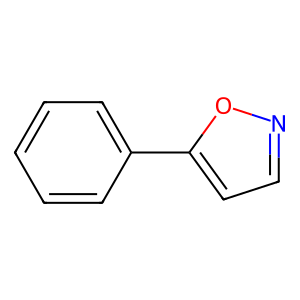

In [9]:
from rdkit import Chem
from rdkit.Chem import Draw

molecule = Chem.MolFromSmiles(held_out_additive)

print("SMILES:", held_out_additive)
print("Molecule parsed successfully:", molecule is not None)

display(Draw.MolToImage(molecule))

In [10]:
from rdkit.Chem import rdFingerprintGenerator

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048,
    includeChirality=True,
)

fingerprint = morgan_generator.GetFingerprint(molecule)

print("Fingerprint length:", fingerprint.GetNumBits())
print("Number of active bits:", fingerprint.GetNumOnBits())
print("First 80 bits:", fingerprint.ToBitString()[:80])

Fingerprint length: 2048
Number of active bits: 20
First 80 bits: 00000000000000000000000000000000000000000000000000000000000000000000000000000000


In [11]:
all_smiles = pd.unique(df[component_columns].to_numpy().ravel())

fingerprint_lookup = {}
invalid_smiles = []

for smiles in all_smiles:
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        invalid_smiles.append(smiles)
    else:
        fingerprint_lookup[smiles] = morgan_generator.GetFingerprint(mol)

print("Unique SMILES:", len(all_smiles))
print("Fingerprints generated:", len(fingerprint_lookup))
print("Invalid SMILES:", len(invalid_smiles))

if invalid_smiles:
    print("Failed SMILES:", invalid_smiles)

Unique SMILES: 44
Fingerprints generated: 44
Invalid SMILES: 0


In [12]:
import numpy as np

fingerprint_arrays = {
    smiles: np.array(list(fp), dtype=np.uint8)
    for smiles, fp in fingerprint_lookup.items()
}

feature_blocks = []
feature_names = []

for role in component_columns:
    block = np.stack([
        fingerprint_arrays[smiles]
        for smiles in df[role]
    ])
    feature_blocks.append(block)
    feature_names.extend([
        f"{role}_bit_{bit}"
        for bit in range(2048)
    ])

X_morgan = pd.DataFrame(
    np.concatenate(feature_blocks, axis=1),
    index=df.index,
    columns=feature_names,
)

print("Morgan feature shape:", X_morgan.shape)
print("Feature value type:", X_morgan.dtypes.iloc[0])
print("First reaction preview:")
display(X_morgan.iloc[:1, :10])

Morgan feature shape: (3955, 8192)
Feature value type: uint8
First reaction preview:


,Aryl halide_bit_0,Aryl halide_bit_1,Aryl halide_bit_2,Aryl halide_bit_3,Aryl halide_bit_4,Aryl halide_bit_5,Aryl halide_bit_6,Aryl halide_bit_7,Aryl halide_bit_8,Aryl halide_bit_9
0,0,0,0,0,0,0,0,0,0,0


In [13]:
assert X_morgan.index.equals(df.index)
assert X_morgan.columns.is_unique
assert X_morgan.isin([0, 1]).all().all()

X_morgan_random_train = X_morgan.loc[random_train.index]
X_morgan_random_test = X_morgan.loc[random_test.index]

X_morgan_additive_train = X_morgan.loc[additive_train.index]
X_morgan_additive_test = X_morgan.loc[additive_test.index]

assert X_morgan_random_train.index.equals(y_random_train.index)
assert X_morgan_random_test.index.equals(y_random_test.index)
assert X_morgan_additive_train.index.equals(y_additive_train.index)
assert X_morgan_additive_test.index.equals(y_additive_test.index)

print("All feature and target alignment checks passed.")
print("Random training features:", X_morgan_random_train.shape)
print("Random test features:", X_morgan_random_test.shape)
print("Additive training features:", X_morgan_additive_train.shape)
print("Additive test features:", X_morgan_additive_test.shape)

All feature and target alignment checks passed.
Random training features: (2768, 8192)
Random test features: (1187, 8192)
Additive training features: (3775, 8192)
Additive test features: (180, 8192)


### 特征工程记录

- 随机拆分使用 `random_state=42`，训练集 2,768 条，测试集 1,187 条。
- 添加剂留出使用按 SMILES 字符串排序后的第一种添加剂，训练集 3,775 条，测试集 180 条。
- 两种拆分保存在 `data/splits/split_manifest.csv`。
- One-hot 编码器分别只在各自训练集上拟合，使用 `handle_unknown="ignore"`。
- 随机拆分的 One-hot 特征有 44 列，添加剂留出的有 43 列。
- Morgan 指纹使用 `radius=2`、`fpSize=2048`、`includeChirality=True`。
- 四个角色按 `Aryl halide`、`Ligand`、`Base`、`Additive` 的顺序拼接，共 8,192 列。
- 44 种 SMILES 均解析成功。特征为 0/1，行索引与对应产率的对齐检查通过。